# NAME: SATYA SRINIVAS PALADUGU
# REGID: BL.AI.U4AID24063

# 23AID472 TEXT ANALYTICS HACKATHON EVALUATION

# AI-powered Research Paper Discovery Assistant
Five domains: **NLP, Healthcare AI, Cybersecurity, Computer Vision, Robotics**.



In [1]:
# 1. Always fetch the latest public code. Rerun after pushing a code change.
import sys, subprocess, tempfile, time
from pathlib import Path
print('START: clone latest public main commit', flush=True)
REPO_URL = 'https://github.com/saltypal/Text_Analytics_Lab_Evaluation.git'
ROOT = Path(tempfile.mkdtemp(prefix='research_lab_checkout_'))
subprocess.run(['git', 'clone', '--depth', '1', '--branch', 'main', REPO_URL, str(ROOT)], check=True)
COMMIT = subprocess.check_output(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'], text=True).strip()
for name in list(sys.modules):
    if name == 'research_assistant' or name.startswith('research_assistant.'):
        del sys.modules[name]
sys.path.insert(0, str(ROOT))
print('DONE: source directory:', ROOT, 'commit:', COMMIT)

START: clone latest public main commit
DONE: source directory: /tmp/research_lab_checkout_fdgwnhhw commit: cc6082367c43c8a5c88f4c0c68822d53d8bbe4d6


In [2]:
# 2. All required packages and the Ollama runtime (Colab/Linux only).
print('START: install packages in the active notebook kernel', flush=True)
%pip install -q -r {ROOT / 'requirements.txt'}
import shutil, platform, urllib.request
if shutil.which('ollama') is None:
    if platform.system() != 'Linux':
        raise RuntimeError('Run this installation cell in Google Colab, not Windows.')
    if shutil.which('zstd') is None:
        subprocess.run(['apt-get', 'update', '-qq'], check=True)
        subprocess.run(['apt-get', 'install', '-y', '-qq', 'zstd'], check=True)
    installer = Path(tempfile.gettempdir()) / 'research_lab_install_ollama.sh'
    urllib.request.urlretrieve('https://ollama.com/install.sh', installer)
    subprocess.run(['sh', str(installer)], check=True)
print('DONE: packages and Ollama installed. Restart only if Colab asks, then rerun from cell 1.')

START: install packages in the active notebook kernel
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
DONE: packages and Ollama installed. Restart only if Colab asks, then rerun from cell 1.


# CONFIGURATION CELL

In [3]:
# 3. ALL adjustable experiment/model settings.
print('START: configuration')
CONFIG = {
    'dataset': 'Q4_Research_Paper_Dataset_1000.csv',
    'seed': 42,
    'test_size': 0.20,
    'preview_papers': 3,
    'bow_top_terms': 20,
    'ngram_orders': [1, 2, 3],
    'ngram_phrases': ['natural language processing', 'patient data', 'robot navigation', 'malware detection'],
    'generated_words': 40,
    'embedding_vocab_limit': 50000,  # First N published pretrained entries; increase for better coverage.
    'static_embeddings': ['Word2Vec', 'GloVe', 'FastText'],
    'bert_model': 'google-bert/bert-base-uncased',
    'bert_batch_size': 16,  # Reduce to 8 if GPU memory is insufficient.
    'bert_max_length': 256,
    'logistic_c': 1.0,
    'svm_c': 1.0,
    'classifier_max_iter': 3000,
    'llm_model': 'qwen3:0.6b',
    'ollama_url': 'http://127.0.0.1:11434',
    'llm_think': False,
    'llm_temperature': 0.0,
    'llm_context': 8192,
    'llm_max_tokens': 128,
    'llm_timeout': 180,
    'shots_per_class': 1,  # Five demonstrations total; only training papers.
    'query': 'patient diagnosis using machine learning',
    'domain_filter': None,  # e.g. 'Healthcare AI'
    'discovery_top_k': 5,
}
print(CONFIG)
print('DONE: config ready. LLM evaluation always uses exactly 10 papers (two per class).')

START: configuration
{'dataset': 'Q4_Research_Paper_Dataset_1000.csv', 'seed': 42, 'test_size': 0.2, 'preview_papers': 3, 'bow_top_terms': 20, 'ngram_orders': [1, 2, 3], 'ngram_phrases': ['natural language processing', 'patient data', 'robot navigation', 'malware detection'], 'generated_words': 40, 'embedding_vocab_limit': 50000, 'static_embeddings': ['Word2Vec', 'GloVe', 'FastText'], 'bert_model': 'google-bert/bert-base-uncased', 'bert_batch_size': 16, 'bert_max_length': 256, 'logistic_c': 1.0, 'svm_c': 1.0, 'classifier_max_iter': 3000, 'llm_model': 'qwen3:0.6b', 'ollama_url': 'http://127.0.0.1:11434', 'llm_think': False, 'llm_temperature': 0.0, 'llm_context': 8192, 'llm_max_tokens': 128, 'llm_timeout': 180, 'shots_per_class': 1, 'query': 'patient diagnosis using machine learning', 'domain_filter': None, 'discovery_top_k': 5}
DONE: config ready. LLM evaluation always uses exactly 10 papers (two per class).


## Setup, environment

In [4]:
print('START: environment setup', flush=True)
import os, json, hashlib, importlib.metadata, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from research_assistant.preprocessing import prepare_data, preprocess_steps, bag_of_words, tokens, LABELS
from research_assistant.classification import train_classifiers, metrics, confusion_plots, misclassified
random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
BASE = Path('/content') if Path('/content').exists() else ROOT
OUT = BASE / 'experiments' / 'lab_evaluation' / 'runs' / (time.strftime('%Y%m%d-%H%M%S')+'-'+str(time.time_ns())[-6:])
OUT.mkdir(parents=True, exist_ok=True)
CACHE = BASE / 'research_lab_cache'; CACHE.mkdir(exist_ok=True)
ENV = {'repository': str(ROOT), 'commit': COMMIT, 'python': sys.version, 'interpreter': sys.executable,
       'packages': {p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','nltk','torch','transformers']},
       'device': 'cuda' if torch.cuda.is_available() else 'cpu',
       'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       'target': 'Google Colab managed Python + requirements.txt in active kernel'}
(OUT/'environment.json').write_text(json.dumps(ENV, indent=2))
(OUT/'config.json').write_text(json.dumps(CONFIG, indent=2))
print(json.dumps(ENV, indent=2)); print('Outputs:', OUT)
# Incremental Python stdout/stderr and cell-status logs. Save .ipynb separately for rich outputs.
ip = get_ipython()
if hasattr(ip, '_lab_hooks'):
    old_pre, old_post = ip._lab_hooks
    ip.events.unregister('pre_run_cell', old_pre); ip.events.unregister('post_run_cell', old_post)
for stream in ['stdout', 'stderr']:
    old = getattr(sys, stream)
    if hasattr(old, '_lab_original'): setattr(sys, stream, old._lab_original)
class Tee:
    def __init__(self, original, path): self._lab_original, self.path = original, path
    def write(self, value):
        self._lab_original.write(value)
        with self.path.open('a', encoding='utf-8') as f: f.write(value)
        return len(value)
    def flush(self): self._lab_original.flush()
    def __getattr__(self, key): return getattr(self._lab_original, key)
state = {}
def before_cell(info):
    state.update(start=time.perf_counter(), cell=hashlib.sha256(info.raw_cell.encode()).hexdigest()[:12])
    print('START cell', state['cell'], flush=True)
def after_cell(result):
    record = {'cell': state.get('cell'), 'execution_count': result.execution_count,
              'elapsed_seconds': round(time.perf_counter()-state.get('start', time.perf_counter()), 3),
              'error': str(result.error_in_exec or result.error_before_exec or '')}
    with (OUT/'cell_status.jsonl').open('a') as f: f.write(json.dumps(record)+'\n')
    print('DONE cell', record, flush=True)
sys.stdout = Tee(sys.stdout, OUT/'stdout.log'); sys.stderr = Tee(sys.stderr, OUT/'stderr.log')
ip.events.register('pre_run_cell', before_cell); ip.events.register('post_run_cell', after_cell)
ip._lab_hooks = (before_cell, after_cell)
RESULTS, PREDICTIONS, MODELS = [], {}, {}
def fit_pair(name, x_train, x_test):
    rows, preds, models = train_classifiers(name, x_train, x_test, TRAIN, TEST,
        seed=CONFIG['seed'], logistic_c=CONFIG['logistic_c'], svm_c=CONFIG['svm_c'], max_iter=CONFIG['classifier_max_iter'])
    RESULTS[:] = [r for r in RESULTS if not r['System'].startswith(name+' +')]+rows
    PREDICTIONS.update(preds); MODELS.update(models)
    pd.DataFrame(RESULTS).to_csv(OUT/'full_test_results.csv', index=False)
    display(pd.DataFrame(rows).round(4))
pd.set_option('display.max_colwidth', 120)
print('DONE: evidence folder writable, logging enabled.')

START: environment setup
{
  "repository": "/tmp/research_lab_checkout_fdgwnhhw",
  "commit": "cc6082367c43c8a5c88f4c0c68822d53d8bbe4d6",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "interpreter": "/usr/bin/python3",
  "packages": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "nltk": "3.9.1",
    "torch": "2.11.0+cu130",
    "transformers": "4.57.6"
  },
  "device": "cuda",
  "gpu": "Tesla T4",
  "target": "Google Colab managed Python + requirements.txt in active kernel"
}
Outputs: /content/experiments/lab_evaluation/runs/20261029-085404-585738
DONE: evidence folder writable, logging enabled.
DONE cell {'cell': None, 'execution_count': 4, 'elapsed_seconds': -0.0, 'error': ''}


## Load, deduplicate and split
# preprocessing

In [5]:
print('START: dataset and split')
DATA = ROOT / CONFIG['dataset']
DF, TRAIN, TEST = prepare_data(DATA, seed=CONFIG['seed'], test_size=CONFIG['test_size'])
ENV['dataset_sha256'] = hashlib.sha256(DATA.read_bytes()).hexdigest()
(OUT/'environment.json').write_text(json.dumps(ENV, indent=2))
TRAIN[['paper_id','research_domain']].to_csv(OUT/'train_split.csv', index=False)
TEST[['paper_id','research_domain']].to_csv(OUT/'test_split.csv', index=False)
display(DF[['paper_id','title','research_domain']].head())
display(pd.DataFrame({'All': DF.research_domain.value_counts(), 'Train': TRAIN.research_domain.value_counts(), 'Test': TEST.research_domain.value_counts()}))
print('DONE: split manifests saved, exact train/test text overlap checked.')

START cell 4a88aa889515
START: dataset and split
Loaded 1000 rows; removed 11 exact text duplicates. Train=791, test=198


,paper_id,title,research_domain
0,RP0522,Improving Disease Progression Modelling Through Gradient-Boosted Trees,Healthcare AI
1,RP0738,Phishing Message Detection Using Character And Word Features,Cybersecurity
2,RP0741,Semantic Similarity Using Contrastive Learning,Natural Language Processing
3,RP0661,Improving Question Answering Through Sequence Labelling,Natural Language Processing
4,RP0412,Robust Patient Risk Stratification in Real-World Electronic Health Records,Healthcare AI


,All,Train,Test
research_domain,,,
Computer Vision,200,160,40
Cybersecurity,197,157,40
Healthcare AI,196,157,39
Natural Language Processing,199,159,40
Robotics,197,158,39


DONE: split manifests saved, exact train/test text overlap checked.
DONE cell {'cell': '4a88aa889515', 'execution_count': 5, 'elapsed_seconds': 0.717, 'error': ''}


## Preprocessing: every stage
Regex tokenization → case folding → English stopword removal → Porter stemming. No NLTK corpus download needed. Stems are used for BoW; natural tokens/text are used for pretrained embeddings so vocabulary and context are preserved.

In [6]:
print('START: preprocessing demonstration')
examples = []
for row in TRAIN.head(CONFIG['preview_papers']).itertuples():
    steps = preprocess_steps(row.text); examples.append(steps)
    display(Markdown('### '+row.paper_id+': '+row.title))
    display(pd.DataFrame([{'Stage': k, 'Output': ' | '.join(v) if isinstance(v,list) else v} for k,v in steps.items()]))
pd.DataFrame(examples).to_csv(OUT/'preprocessing_examples.csv', index=False)
print('DONE: examples saved.')

START cell 1befd11f3986
START: preprocessing demonstration


### RP0941: Improving Semantic Similarity Through Prompt-Based Learning

,Stage,Output
0,original,"Improving Semantic Similarity Through Prompt-Based Learning. This study investigates semantic similarity, focusing o..."
1,tokenization,Improving | Semantic | Similarity | Through | Prompt | Based | Learning | This | study | investigates | semantic | s...
2,case_folding,improving | semantic | similarity | through | prompt | based | learning | this | study | investigates | semantic | s...
3,stopword_removal,improving | semantic | similarity | prompt | based | learning | study | investigates | semantic | similarity | focus...
4,stemming,improv | semant | similar | prompt | base | learn | studi | investig | semant | similar | focus | estim | text | pas...
5,processed,improv semant similar prompt base learn studi investig semant similar focus estim text passag express relat mean app...


### RP0458: Evaluating Ensemble Classification for Security Incident Report Analysis

,Stage,Output
0,original,Evaluating Ensemble Classification for Security Incident Report Analysis. This study investigates security incident ...
1,tokenization,Evaluating | Ensemble | Classification | for | Security | Incident | Report | Analysis | This | study | investigates...
2,case_folding,evaluating | ensemble | classification | for | security | incident | report | analysis | this | study | investigates...
3,stopword_removal,evaluating | ensemble | classification | security | incident | report | analysis | study | investigates | security |...
4,stemming,evalu | ensembl | classif | secur | incid | report | analysi | studi | investig | secur | incid | report | analysi |...
5,processed,evalu ensembl classif secur incid report analysi studi investig secur incid report analysi focus extract use inform ...


### RP0252: Evaluating Gradient-Boosted Trees for Clinical Decision Support

,Stage,Output
0,original,"Evaluating Gradient-Boosted Trees for Clinical Decision Support. This study investigates clinical decision support, ..."
1,tokenization,Evaluating | Gradient | Boosted | Trees | for | Clinical | Decision | Support | This | study | investigates | clinic...
2,case_folding,evaluating | gradient | boosted | trees | for | clinical | decision | support | this | study | investigates | clinic...
3,stopword_removal,evaluating | gradient | boosted | trees | clinical | decision | support | study | investigates | clinical | decision...
4,stemming,evalu | gradient | boost | tree | clinic | decis | support | studi | investig | clinic | decis | support | focus | p...
5,processed,evalu gradient boost tree clinic decis support studi investig clinic decis support focus provid evid inform recommen...


DONE: examples saved.
DONE cell {'cell': '1befd11f3986', 'execution_count': 6, 'elapsed_seconds': 0.045, 'error': ''}


## Bag of Words
Fit vocabulary on training data only. Matrix entries count stemmed words; show five papers and the most frequent training terms.

In [7]:
print('START: Bag of Words')
BOW, BOW_TRAIN, BOW_TEST = bag_of_words(TRAIN, TEST)
terms = BOW.get_feature_names_out()
counts = np.asarray(BOW_TRAIN.sum(axis=0)).ravel()
top = counts.argsort()[-CONFIG['bow_top_terms']:][::-1]
display(pd.DataFrame(BOW_TRAIN[:5,top].toarray(), columns=terms[top], index=TRAIN.paper_id.head(5)))
table = pd.DataFrame({'Term': terms[top], 'Train count': counts[top]})
display(table); table.to_csv(OUT/'bow_top_terms.csv', index=False)
print('DONE:', BOW_TRAIN.shape, BOW_TEST.shape)

START cell 75430c402d6f
START: Bag of Words
Bag of Words: train=(791, 334), test=(198, 334); vocabulary fitted on training only.


,gener,evalu,studi,analysi,limit,inform,pattern,data,error,discuss,investig,constraint,drawn,direct,examin,experi,futur,focus,result,qualiti
paper_id,,,,,,,,,,,,,,,,,,,,
RP0941,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
RP0458,1,2,1,3,2,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1
RP0252,1,2,1,1,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1
RP0362,1,1,1,1,1,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1
RP0493,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


,Term,Train count
0,gener,1007
1,evalu,982
2,studi,948
3,analysi,925
4,limit,884
5,inform,882
6,pattern,882
7,data,840
8,error,831
9,discuss,818


DONE: (791, 334) (198, 334)
DONE cell {'cell': '75430c402d6f', 'execution_count': 7, 'elapsed_seconds': 0.087, 'error': ''}


## Unigram, bigram and trigram language models
Use training text tokens with stopwords retained for readable samples. Laplace-smoothed probabilities: `P(w|h)=(count(h,w)+1)/(count(h)+vocabulary_size)`. Sequence probability includes start context, excludes end token. Generation samples observed counts (unsmoothed empirical model).

In [8]:
from research_assistant.ngrams import NGramLM
print('START: n-gram training')
LMS = {n: NGramLM(n).fit([tokens(t) for t in TRAIN.text]) for n in CONFIG['ngram_orders']}
rows = []
for n, lm in LMS.items():
    for phrase in CONFIG['ngram_phrases']:
        words = tokens(phrase); probability, logp = lm.sequence_probability(words)
        rows.append({'Order':n, 'Sequence':phrase, 'Probability':probability, 'Log probability':logp,
                     'P(last|context)':lm.probability(words[-1], words[:-1])})
    print(f'{n}-gram generated sample:', lm.generate(CONFIG['generated_words'], CONFIG['seed']))
table = pd.DataFrame(rows)
display(table.style.format({'Probability':'{:.8e}', 'Log probability':'{:.3f}', 'P(last|context)':'{:.6f}'}))
table.to_csv(OUT/'ngram_probabilities.csv', index=False)
print('DONE: three models, selected probabilities and samples.')

START cell 98d811eb6845
START: n-gram training
1-gram generated sample: evaluation this experiments from graph gradient predictions on constraints this from also this drawn
2-gram generated sample: an empirical study investigates electronic health record analysis also discusses limitations data quality and directions for future evaluation
3-gram generated sample: an empirical study of large language model evaluation focusing on recognizing language patterns used to manipulate recipients we apply prompt based learning to information drawn from electronic health record analysis through transformer encoders this study investigates software vulnerability summarization focusing


,Order,Sequence,Probability,Log probability,P(last|context)
0,1,natural language processing,7.29182407e-11,-23.342,0.000019
1,1,patient data,4.76702539e-05,-9.951,0.016031
2,1,robot navigation,6.13918572e-06,-12.001,0.000915
3,1,malware detection,7.12168797e-08,-16.458,0.003736
4,2,natural language processing,1.01893526e-06,-13.797,0.001757
5,2,patient data,1.95915297e-04,-8.538,0.081566
6,2,robot navigation,2.07830046e-04,-8.479,0.025958
7,2,malware detection,1.74812339e-06,-13.257,0.002183
8,3,natural language processing,1.64494940e-07,-15.620,0.001946
9,3,patient data,5.22156856e-06,-12.163,0.002174


DONE: three models, selected probabilities and samples.
DONE cell {'cell': '98d811eb6845', 'execution_count': 8, 'elapsed_seconds': 0.222, 'error': ''}


## BoW baseline: Logistic Regression and Linear SVM
Quick pipeline check before pretrained downloads. All embedding cells below train these same **two** classifiers with the same split and settings.

In [9]:
print('START: baseline')
fit_pair('Bag of Words', BOW_TRAIN, BOW_TEST)
print('DONE: baseline')

START cell 52f40853eb4f
START: baseline
Training Bag of Words + Logistic Regression ...
Completed in 0.0s; accuracy=1.000
Training Bag of Words + Linear SVM ...
Completed in 0.0s; accuracy=1.000


,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Bag of Words + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
1,Bag of Words + Linear SVM,Full test,198,1.0,1.0,1.0,1.0


DONE: baseline
DONE cell {'cell': '52f40853eb4f', 'execution_count': 9, 'elapsed_seconds': 0.107, 'error': ''}


## Pretrained Word2Vec + both classifiers
Average matched pretrained Google News word vectors. Stream the first configured number of published entries to save bandwidth; cache only dataset words. Missing words are skipped. Coverage and zero-vector documents are printed. This is explicitly a limited-vocabulary evaluation.

In [10]:
from research_assistant.embeddings import load_static_vectors, mean_embeddings, bert_embeddings
print('START: static embedding setup')
VOCABULARY = set(w for text in DF.text for w in tokens(text))
def run_static(name):
    vectors, dim = load_static_vectors(name, VOCABULARY, CACHE, limit=CONFIG['embedding_vocab_limit'])
    x_train = mean_embeddings(TRAIN.text.tolist(), vectors, dim)
    x_test = mean_embeddings(TEST.text.tolist(), vectors, dim)
    np.savez_compressed(OUT/(name.lower()+'_embeddings.npz'), train=x_train, test=x_test)
    fit_pair(name, x_train, x_test)
    print('DONE:', name, 'with BOTH classifiers')
run_static(CONFIG['static_embeddings'][0])

START cell d33015715046
START: static embedding setup
Word2Vec: streaming at most 50,000 pretrained entries; retaining dataset words only.
Source: https://github.com/piskvorky/gensim-data/releases/download/word2vec-google-news-300/word2vec-google-news-300.gz


Word2Vec entries:   0%|          | 0/50000 [00:00<?, ?it/s]

Word2Vec: retained 419/456 distinct dataset words in 1.2s.
Token coverage: 87.4%; zero-vector documents: 0/791
Token coverage: 87.3%; zero-vector documents: 0/198
Training Word2Vec + Logistic Regression ...
Completed in 0.2s; accuracy=1.000
Training Word2Vec + Linear SVM ...
Completed in 0.1s; accuracy=1.000


,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Word2Vec + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
1,Word2Vec + Linear SVM,Full test,198,1.0,1.0,1.0,1.0


DONE: Word2Vec with BOTH classifiers
DONE cell {'cell': 'd33015715046', 'execution_count': 10, 'elapsed_seconds': 1.764, 'error': ''}


## Pretrained GloVe + both classifiers
50-dimensional Wikipedia/Gigaword embeddings; same pooling, split and classifiers.

In [11]:
print('START: GloVe')
run_static(CONFIG['static_embeddings'][1])

START cell 066ea064dec3
START: GloVe
GloVe: streaming at most 50,000 pretrained entries; retaining dataset words only.
Source: https://github.com/piskvorky/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz


GloVe entries:   0%|          | 0/50000 [00:00<?, ?it/s]

GloVe: retained 435/456 distinct dataset words in 0.8s.
Token coverage: 97.9%; zero-vector documents: 0/791
Token coverage: 97.7%; zero-vector documents: 0/198
Training GloVe + Logistic Regression ...
Completed in 0.1s; accuracy=1.000
Training GloVe + Linear SVM ...
Completed in 0.0s; accuracy=1.000


,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,GloVe + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
1,GloVe + Linear SVM,Full test,198,1.0,1.0,1.0,1.0


DONE: GloVe with BOTH classifiers
DONE cell {'cell': '066ea064dec3', 'execution_count': 11, 'elapsed_seconds': 0.995, 'error': ''}


## Pretrained FastText + both classifiers
Exported 300-dimensional Wikipedia/news word vectors were pretrained with subwords. The export does not include a subword model, so unseen-word synthesis is unavailable. Token coverage makes this limitation visible.

In [12]:
print('START: FastText')
run_static(CONFIG['static_embeddings'][2])

START cell 54dd9d45e09d
START: FastText
FastText: streaming at most 50,000 pretrained entries; retaining dataset words only.
Source: https://github.com/piskvorky/gensim-data/releases/download/fasttext-wiki-news-subwords-300/fasttext-wiki-news-subwords-300.gz


FastText entries:   0%|          | 0/50000 [00:00<?, ?it/s]

FastText: retained 444/456 distinct dataset words in 2.2s.
Token coverage: 98.6%; zero-vector documents: 0/791
Token coverage: 98.5%; zero-vector documents: 0/198
Training FastText + Logistic Regression ...
Completed in 0.7s; accuracy=1.000
Training FastText + Linear SVM ...
Completed in 0.2s; accuracy=1.000


,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,FastText + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
1,FastText + Linear SVM,Full test,198,1.0,1.0,1.0,1.0


DONE: FastText with BOTH classifiers
DONE cell {'cell': '54dd9d45e09d', 'execution_count': 12, 'elapsed_seconds': 3.279, 'error': ''}


## Pretrained BERT + both classifiers
Frozen BERT on natural text; attention-mask mean pooling. No BERT fine-tuning. Batch size and maximum token length are configurable above.

In [13]:
print('START: BERT', flush=True)
matrix = bert_embeddings(TRAIN.text.tolist()+TEST.text.tolist(), CACHE,
    model_name=CONFIG['bert_model'], batch_size=CONFIG['bert_batch_size'], max_length=CONFIG['bert_max_length'])
fit_pair('BERT', matrix[:len(TRAIN)], matrix[len(TRAIN):])
print('DONE: BERT with BOTH classifiers')

START cell 13b7449d334b
START: BERT
BERT: google-bert/bert-base-uncased, device=cuda, max_length=256, masked mean pooling.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

BERT batches:   0%|          | 0/62 [00:00<?, ?it/s]

BERT complete: (989, 768); cache=/content/research_lab_cache/bert-7ee9bd20bbeaf03f.npy
Training BERT + Logistic Regression ...
Completed in 0.3s; accuracy=1.000
Training BERT + Linear SVM ...
Completed in 0.2s; accuracy=1.000


,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,BERT + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
1,BERT + Linear SVM,Full test,198,1.0,1.0,1.0,1.0


DONE: BERT with BOTH classifiers
DONE cell {'cell': '13b7449d334b', 'execution_count': 13, 'elapsed_seconds': 35.952, 'error': ''}


## Ollama Qwen3: zero-shot and few-shot
Start local Ollama and download `qwen3:0.6b`. Zero-shot: descriptions only. Few-shot: one training example per domain by default. Evaluate the same 10 held-out papers (two per domain). Thinking disabled; schema constrains JSON to the five labels. Invalid output counts as an error, never as a fabricated fallback label.

In [14]:
from research_assistant.llm import start_ollama, select_ten, classify_ten
print('START: Ollama setup and LLM evaluation', flush=True)
start_ollama(CONFIG['ollama_url'], CONFIG['llm_model'], OUT)
TEN, TEN_INDICES = select_ten(TEST, CONFIG['seed'])
LLM_PREDICTIONS = classify_ten(TRAIN, TEN, OUT, CONFIG)
LLM_TABLE = TEN[['paper_id','title','research_domain']].reset_index(drop=True)
for name, pred in LLM_PREDICTIONS.items(): LLM_TABLE[name] = pred
display(LLM_TABLE)
LLM_TABLE.to_csv(OUT/'llm_comparison_10.csv', index=False)
print('DONE: prompts, raw responses and predictions saved incrementally.')

START cell 6aa4ed1fba03
START: Ollama setup and LLM evaluation
Pulling qwen3:0.6b; download progress follows.
Ollama ready: qwen3:0.6b
Zero-shot LLM: paper 1/10 (RP0156)
Prediction: Natural Language Processing
Zero-shot LLM: paper 2/10 (RP0206)
Prediction: Natural Language Processing
Zero-shot LLM: paper 3/10 (RP0167)
Prediction: Natural Language Processing
Zero-shot LLM: paper 4/10 (RP0297)
Prediction: Natural Language Processing
Zero-shot LLM: paper 5/10 (RP0893)
Prediction: Natural Language Processing
Zero-shot LLM: paper 6/10 (RP0208)
Prediction: Natural Language Processing
Zero-shot LLM: paper 7/10 (RP0779)
Prediction: Computer Vision
Zero-shot LLM: paper 8/10 (RP0564)
Prediction: Computer Vision
Zero-shot LLM: paper 9/10 (RP0220)
Prediction: Computer Vision
Zero-shot LLM: paper 10/10 (RP0695)
Prediction: Natural Language Processing
Few-shot LLM: paper 1/10 (RP0156)
Prediction: Natural Language Processing
Few-shot LLM: paper 2/10 (RP0206)
Prediction: Natural Language Processing
Fe

,paper_id,title,research_domain,Zero-shot LLM,Few-shot LLM
0,RP0156,An Empirical Study of Information Extraction for Customer Reviews,Natural Language Processing,Natural Language Processing,Natural Language Processing
1,RP0206,Robust Text Summarization in Real-World News Articles,Natural Language Processing,Natural Language Processing,Natural Language Processing
2,RP0167,An Empirical Study of Clinical Decision Support for Medical Literature,Healthcare AI,Natural Language Processing,Healthcare AI
3,RP0297,Evaluating Temporal Modelling for Electronic Health Record Analysis,Healthcare AI,Natural Language Processing,Healthcare AI
4,RP0893,Improving Software Vulnerability Summarization Through Graph-Based Learning,Cybersecurity,Natural Language Processing,Natural Language Processing
5,RP0208,Evaluating Graph-Based Learning for Security Incident Report Analysis,Cybersecurity,Natural Language Processing,Cybersecurity
6,RP0779,Image Retrieval Using Multimodal Encoders,Computer Vision,Computer Vision,Computer Vision
7,RP0564,Image Retrieval Using Convolutional Neural Networks,Computer Vision,Computer Vision,Computer Vision
8,RP0220,Robust Robot Navigation in Real-World Control Sequences,Robotics,Computer Vision,Robotics
9,RP0695,Evaluating Reinforcement Learning for Human-Robot Interaction,Robotics,Natural Language Processing,Robotics


DONE: prompts, raw responses and predictions saved incrementally.
DONE cell {'cell': '6aa4ed1fba03', 'execution_count': 14, 'elapsed_seconds': 109.433, 'error': ''}


## Comparison tables
Macro precision/recall/F1 weight each domain equally. Full-test ML scores and paired 10-paper scores are separate. **Compare LLM and ML using the paired table.** Ten observations are a small demonstration, not reliable evidence of a model ranking. Corpus, dimension and limited vocabulary also affect embedding comparisons.

In [15]:
print('START: final comparison tables')
FULL_TABLE = pd.DataFrame(RESULTS).sort_values('F1 (macro)', ascending=False)
display(Markdown('### Full test set: ML systems')); display(FULL_TABLE.round(4))
PAIRED = {name: np.asarray(pred)[TEN_INDICES] for name,pred in PREDICTIONS.items()}
PAIRED.update(LLM_PREDICTIONS)
PAIRED_TABLE = pd.DataFrame([metrics(name, TEN.research_domain, pred, 'Same 10 papers') for name,pred in PAIRED.items()]).sort_values('F1 (macro)', ascending=False)
display(Markdown('### Identical 10 test papers: all systems')); display(PAIRED_TABLE.round(4))
FULL_TABLE.to_csv(OUT/'full_test_results.csv', index=False)
PAIRED_TABLE.to_csv(OUT/'paired_10_results.csv', index=False)
for name,pred in PREDICTIONS.items():
    pd.DataFrame({'System':name, 'paper_id':TEST.paper_id, 'True':TEST.research_domain, 'Predicted':pred}).to_csv(OUT/(name.replace(' ','_').replace('+','plus')+'_predictions.csv'), index=False)
print('DONE: comparison tables and every ML prediction saved.')

START cell 6d5a64f82e45
START: final comparison tables


### Full test set: ML systems

,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Bag of Words + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
1,Bag of Words + Linear SVM,Full test,198,1.0,1.0,1.0,1.0
2,Word2Vec + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
3,Word2Vec + Linear SVM,Full test,198,1.0,1.0,1.0,1.0
4,GloVe + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
5,GloVe + Linear SVM,Full test,198,1.0,1.0,1.0,1.0
6,FastText + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
7,FastText + Linear SVM,Full test,198,1.0,1.0,1.0,1.0
8,BERT + Logistic Regression,Full test,198,1.0,1.0,1.0,1.0
9,BERT + Linear SVM,Full test,198,1.0,1.0,1.0,1.0


### Identical 10 test papers: all systems

,System,Scope,N,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Bag of Words + Logistic Regression,Same 10 papers,10,1.0,1.0000,1.0,1.0000
1,Bag of Words + Linear SVM,Same 10 papers,10,1.0,1.0000,1.0,1.0000
2,Word2Vec + Logistic Regression,Same 10 papers,10,1.0,1.0000,1.0,1.0000
3,Word2Vec + Linear SVM,Same 10 papers,10,1.0,1.0000,1.0,1.0000
4,GloVe + Logistic Regression,Same 10 papers,10,1.0,1.0000,1.0,1.0000
5,GloVe + Linear SVM,Same 10 papers,10,1.0,1.0000,1.0,1.0000
6,FastText + Logistic Regression,Same 10 papers,10,1.0,1.0000,1.0,1.0000
7,FastText + Linear SVM,Same 10 papers,10,1.0,1.0000,1.0,1.0000
8,BERT + Logistic Regression,Same 10 papers,10,1.0,1.0000,1.0,1.0000
9,BERT + Linear SVM,Same 10 papers,10,1.0,1.0000,1.0,1.0000


DONE: comparison tables and every ML prediction saved.
DONE cell {'cell': '6d5a64f82e45', 'execution_count': 15, 'elapsed_seconds': 0.134, 'error': ''}


## Confusion matrices and misclassified-paper analysis
Rows = true domain, columns = predicted domain. Read the abstracts behind off-diagonal entries; overlapping vocabulary is a possible explanation, not a demonstrated cause. No errors on this templated dataset would not establish real-world generalization.

START cell a082f0778d30
START: confusion matrices and error inspection


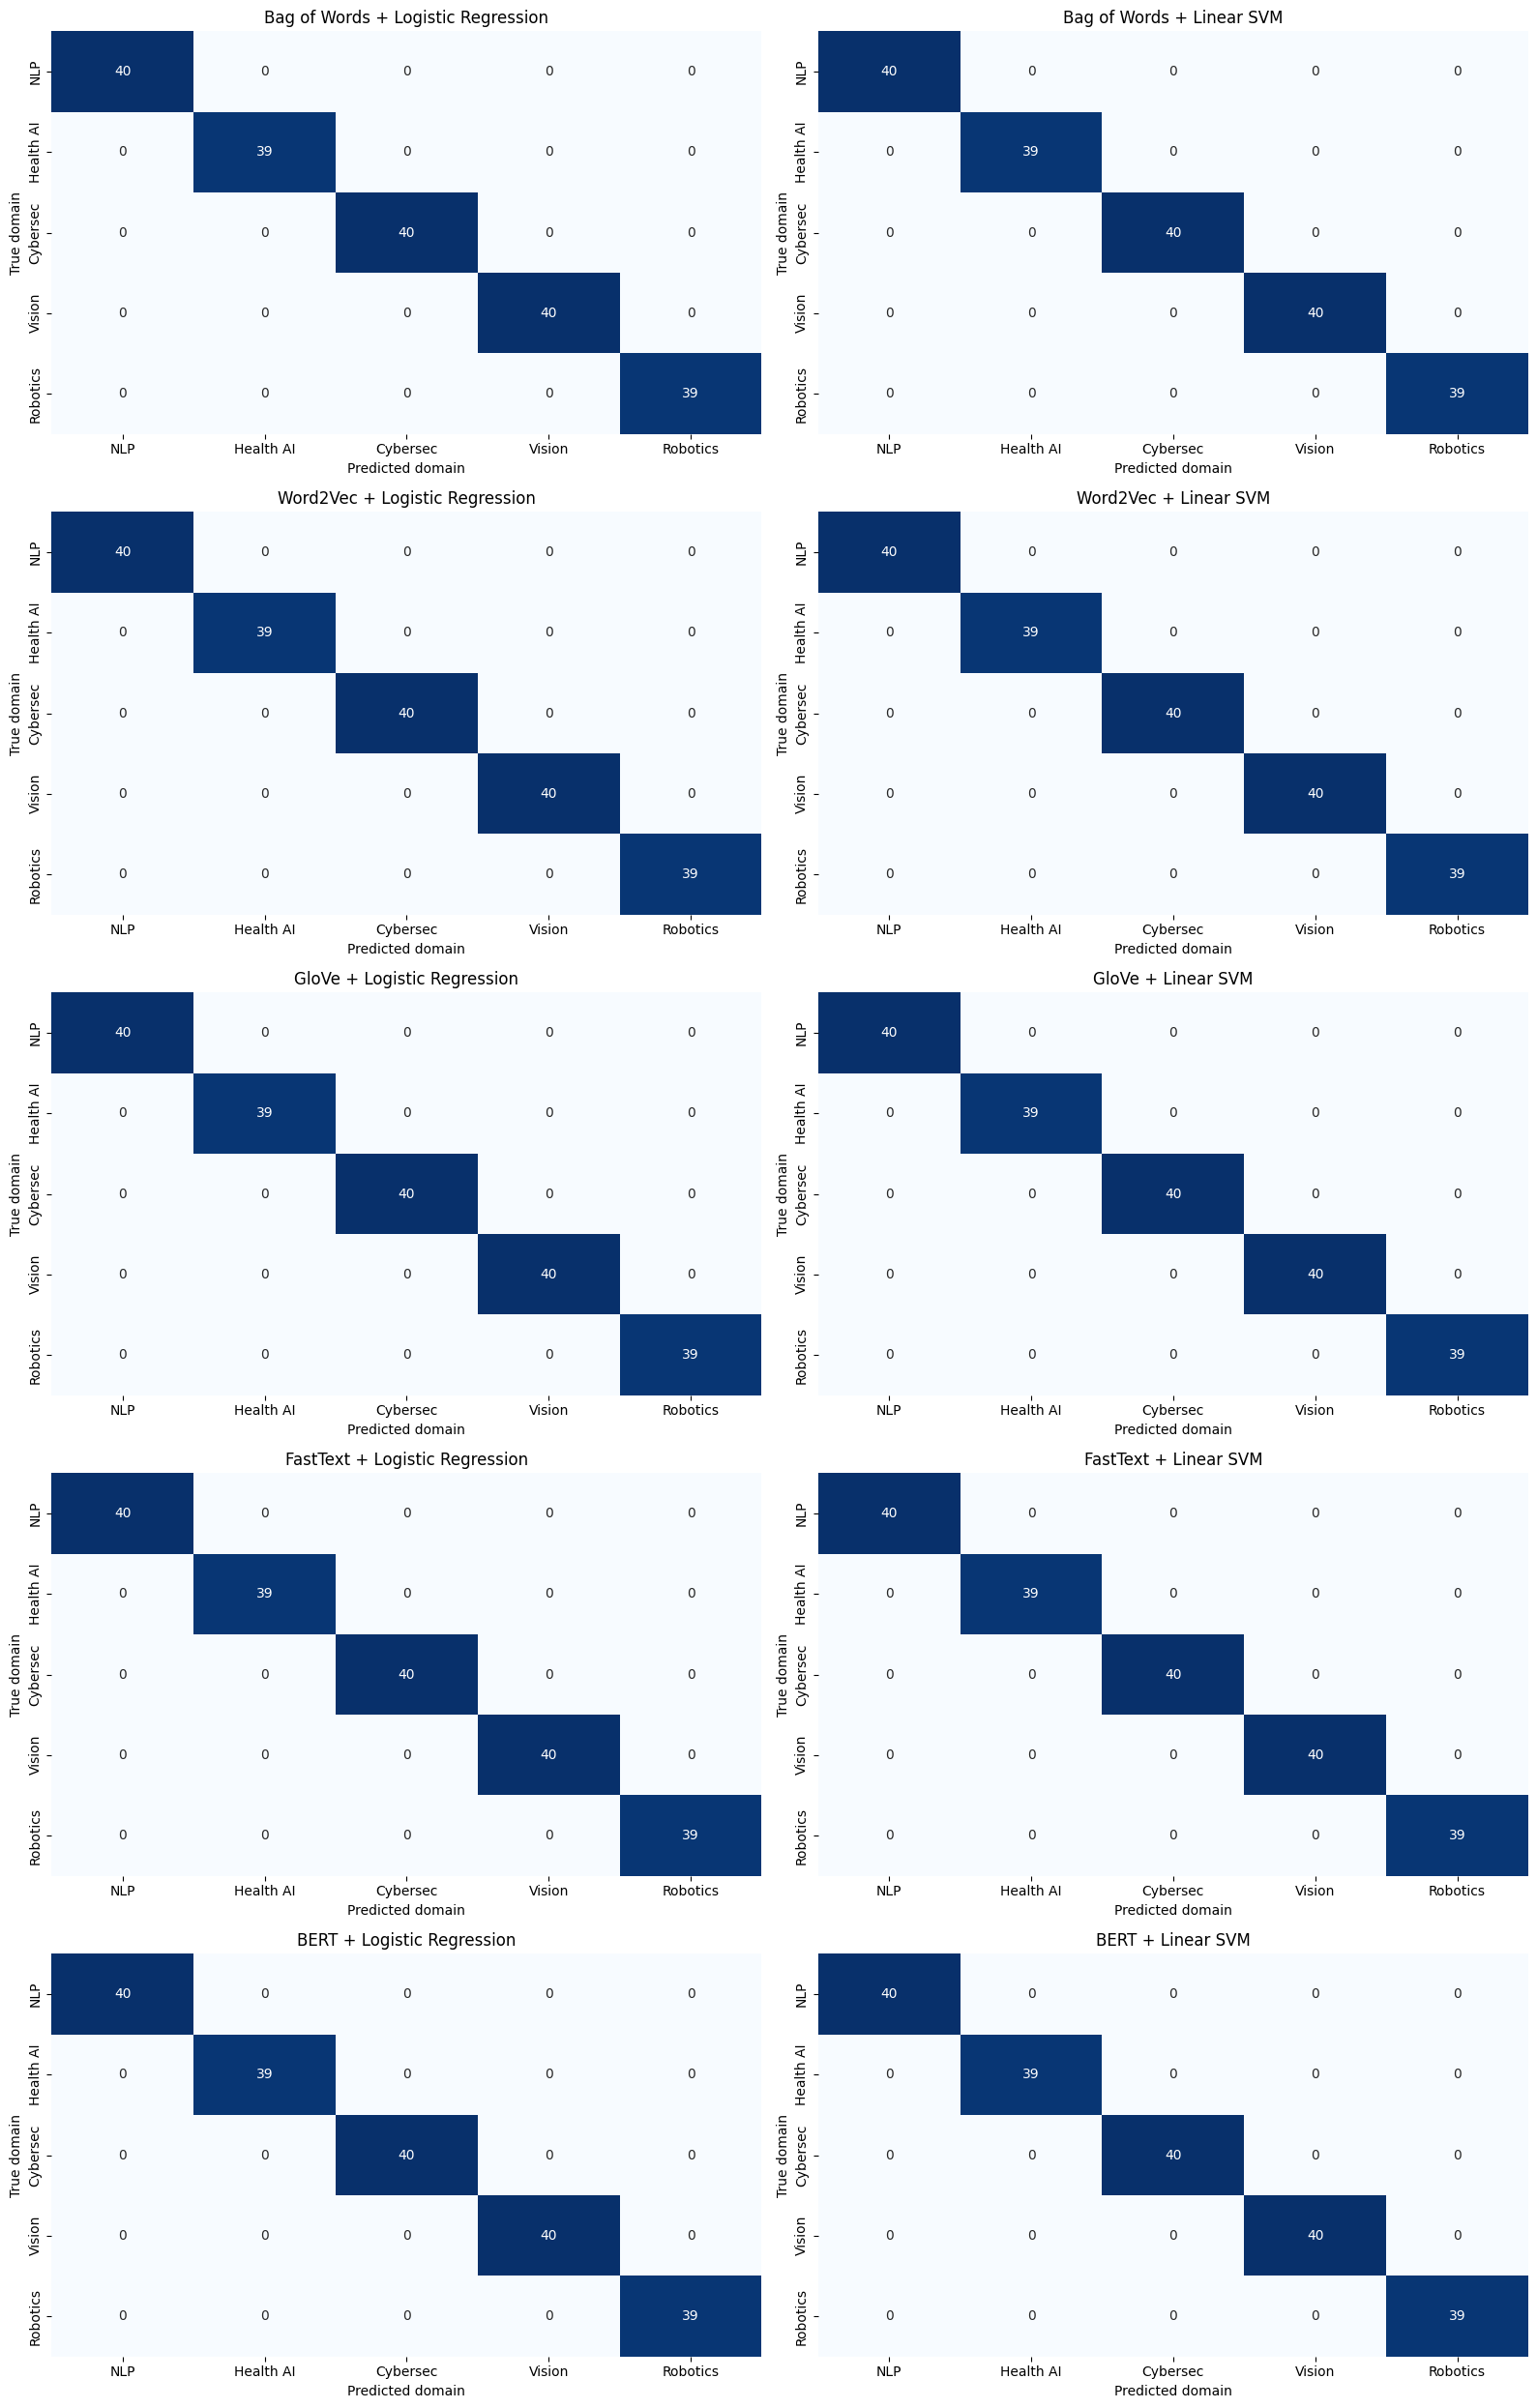

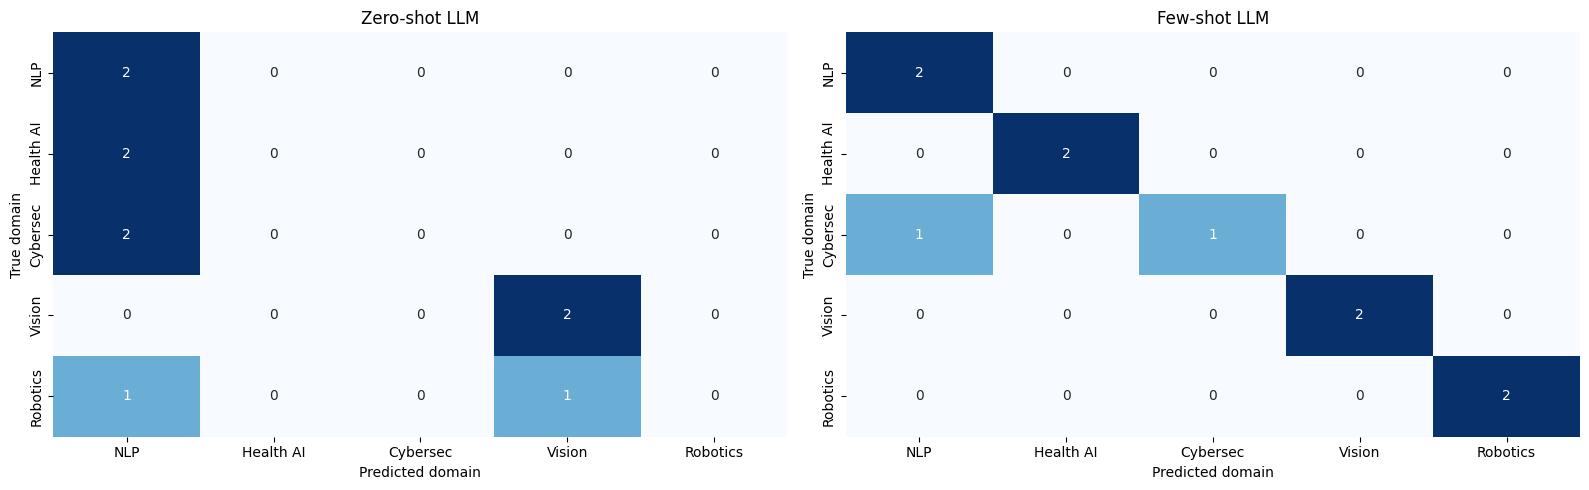

,paper_id,title,abstract,research_domain,Predicted,System
0,RP0167,An Empirical Study of Clinical Decision Support for Medical Literature,"This study investigates clinical decision support, focusing on providing evidence-informed recommendations to assist...",Healthcare AI,Natural Language Processing,Zero-shot LLM
1,RP0297,Evaluating Temporal Modelling for Electronic Health Record Analysis,"This study investigates electronic health record analysis, focusing on using longitudinal patient records to discove...",Healthcare AI,Natural Language Processing,Zero-shot LLM
2,RP0893,Improving Software Vulnerability Summarization Through Graph-Based Learning,"This study investigates software vulnerability summarization, focusing on creating concise summaries of technical vu...",Cybersecurity,Natural Language Processing,Zero-shot LLM
3,RP0208,Evaluating Graph-Based Learning for Security Incident Report Analysis,"This study investigates security incident report analysis, focusing on extracting useful information from incident d...",Cybersecurity,Natural Language Processing,Zero-shot LLM
4,RP0220,Robust Robot Navigation in Real-World Control Sequences,"This study investigates robot navigation, focusing on planning safe routes through changing environments. We apply s...",Robotics,Computer Vision,Zero-shot LLM
5,RP0695,Evaluating Reinforcement Learning for Human-Robot Interaction,"This study investigates human-robot interaction, focusing on enabling natural and safe communication between people ...",Robotics,Natural Language Processing,Zero-shot LLM
6,RP0893,Improving Software Vulnerability Summarization Through Graph-Based Learning,"This study investigates software vulnerability summarization, focusing on creating concise summaries of technical vu...",Cybersecurity,Natural Language Processing,Few-shot LLM


,System,research_domain,Predicted,Count
1,Zero-shot LLM,Cybersecurity,Natural Language Processing,2
2,Zero-shot LLM,Healthcare AI,Natural Language Processing,2
0,Few-shot LLM,Cybersecurity,Natural Language Processing,1
3,Zero-shot LLM,Robotics,Computer Vision,1
4,Zero-shot LLM,Robotics,Natural Language Processing,1


Read each title and abstract above: identify shared terms, ambiguous domains or missing embedding vocabulary before assigning a cause.

DONE: figures, error titles and full abstracts saved.
DONE cell {'cell': 'a082f0778d30', 'execution_count': 16, 'elapsed_seconds': 5.517, 'error': ''}


In [16]:
print('START: confusion matrices and error inspection')
confusion_plots(PREDICTIONS, TEST, OUT, 'full_test')
confusion_plots(LLM_PREDICTIONS, TEN, OUT, 'llm_10')
ERRORS = pd.concat([misclassified(PREDICTIONS, TEST), misclassified(LLM_PREDICTIONS, TEN)], ignore_index=True)
ERRORS.to_csv(OUT/'misclassified_papers.csv', index=False)
if ERRORS.empty:
    print('No errors among completed systems. This does not prove generalization beyond this dataset.')
else:
    display(ERRORS)
    display(ERRORS.groupby(['System','research_domain','Predicted']).size().rename('Count').reset_index().sort_values('Count', ascending=False))
    display(Markdown('Read each title and abstract above: identify shared terms, ambiguous domains or missing embedding vocabulary before assigning a cause.'))
print('DONE: figures, error titles and full abstracts saved.')

## Simple paper discovery
Change query and optional predicted-domain filter in CONFIG. Retrieval uses cosine similarity in training-fitted BoW space; domain labels below are model predictions.

In [17]:
from sklearn.metrics.pairwise import cosine_similarity
print('START: discovery query:', CONFIG['query'])
query_vector = BOW.transform([preprocess_steps(CONFIG['query'])['processed']])
all_vectors = BOW.transform(DF.processed)
found = DF[['paper_id','title']].copy()
found['Similarity'] = cosine_similarity(query_vector, all_vectors).ravel()
found['Predicted domain'] = MODELS['Bag of Words + Logistic Regression'].predict(all_vectors)
if CONFIG['domain_filter']: found = found[found['Predicted domain']==CONFIG['domain_filter']]
display(found.sort_values('Similarity', ascending=False).head(CONFIG['discovery_top_k']))
print('DONE: discovery results.')

START cell 32444b2e04ea
START: discovery query: patient diagnosis using machine learning


,paper_id,title,Similarity,Predicted domain
900,RP0477,Improving Patient Risk Stratification Through Explainable Machine Learning,0.471405,Healthcare AI
793,RP0557,Improving Patient Risk Stratification Through Explainable Machine Learning,0.434122,Healthcare AI
942,RP0687,Treatment Recommendation Using Explainable Machine Learning,0.434122,Healthcare AI
462,RP0962,Improving Disease Progression Modelling Through Explainable Machine Learning,0.412479,Healthcare AI
306,RP0577,Brain Tumour Outcome Prediction Using Explainable Machine Learning,0.409644,Healthcare AI


DONE: discovery results.
DONE cell {'cell': '32444b2e04ea', 'execution_count': 17, 'elapsed_seconds': 0.065, 'error': ''}


## Download results
ZIP includes metrics, plots, split manifests, configuration, environment, prompts, predictions and logs. Save the executed notebook separately for rich outputs. Colab `/content` is temporary; download before disconnecting. Caches allow reuse within the current runtime; this is not training-checkpoint resume.

In [18]:
import shutil
print('START: package run evidence', OUT)
archive = shutil.make_archive(str(OUT), 'zip', root_dir=OUT)
print('DONE: results ZIP:', archive)
try:
    from google.colab import files
except ImportError:
    print('Local run ZIP:', archive)
else:
    files.download(archive)

START cell 8818d5a5031d
START: package run evidence /content/experiments/lab_evaluation/runs/20261029-085404-585738
DONE: results ZIP: /content/experiments/lab_evaluation/runs/20261029-085404-585738.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DONE cell {'cell': '8818d5a5031d', 'execution_count': 18, 'elapsed_seconds': 0.107, 'error': ''}
